# Lab V: Matrix multiplication

**Name: Andrés Sanchez-Toril**

# **Introduction**  

In this practice, we will explore how to perform matrix multiplication using photonic chips. 

## **Main Objectives:**   
- Implement matrix multiplication using MZI networks.  
- Simulate errors and study their impact on the system.  
- Develop a scalable system for advanced photonic applications. 


# **Section 1: Implementing the Photonic Vector for Matrix Multiplication**  



### **MZI with Two Internal Phase Shifters**  

The vector we will use is constructed from an array of MZIs with two internal phase shifters. These phase shifters allow control over both the amplitude and phase of the output. The system design, as mentioned, is illustrated below.

<img src="images/vmm.png" alt="Drawing" style="width: 700px;"/>

---

### **Transfer Function of the MZI with Two Phase Shifters**  

The transfer matrix of the MZI with two phase shifters is:

$$
M_{\text{MZI}} = \frac{ie^{i\frac{\theta_1 + \theta_2}{2}}}{\sqrt{2}} \begin{bmatrix} 
\sin\left(\frac{\theta_1 - \theta_2}{2}\right) & \cos\left(\frac{\theta_1 - \theta_2}{2}\right) \\
\cos\left(\frac{\theta_1 - \theta_2}{2}\right) & \sin\left(\frac{\theta_1 - \theta_2}{2}\right)
\end{bmatrix}
$$

Where:
- $ \theta_1 $ and $ \theta_2 $ are the phase shifts introduced by the two internal phase shifters.  
- The relation for these phase shifts depends on the desired complex output at the cross port of the MZI.  

---

### **Objective:**  
In this section, we will implement the vector that will be multiplied by the photonic matrix. The vector is constructed using an array of MZIs with two internal phase shifters that allow us to control the amplitude and phase at the output. We will perform the following tasks:  

1. **Create a function** that, given a complex number, returns the phases that must be set on the phase shifters to achieve that complex number at the output of the cross port of the MZI.  
2. **Create a function** that does the same for a vector of complex numbers of size $ N $.  
3. **Implement a function** to introduce errors in the phase values and compute the **Root Mean Square Error (RMSE)** between the ideal vector and the obtained one.  
4. **Plot the RMSE** to visualize the impact of the errors on the system.  

---

### **Exercise 1: Calculate the Phases $\theta_1$ and $\theta_2$**

In this exercise, we will create a function to calculate the phase shifts $\theta_1$ and $\theta_2$ for a given complex number. Given a complex number $ z = A \exp(i \phi) $, where $ A $ is the amplitude and $ \phi $ is the phase, we can calculate the phase shifts $ \theta_1 $ and $ \theta_2 $ required to obtain this complex number at the cross port as follows: 

$$
\theta_1 = \phi + \arccos(A) 
$$

$$
\theta_2 = \phi - \arccos(A) 
$$


Next, we will create a function that loops through a vector of $N$ complex numbers to calculate the corresponding $\theta_1$ and $\theta_2$ values for each.

In [1]:
import numpy as np

def compute_phases_for_complex_number(z):
    """
    Given a complex number z = A * exp(i * phi), calculate the phase shifts theta1 and theta2
    required to achieve this complex number at the cross port of the MZI.
    """
    # Extract the amplitude and phase of the complex number
    A = np.abs(z)
    phi = np.angle(z)
    
    # Calculate the required phase shifts
    theta1 = phi + np.arccos(A)
    theta2 = phi - np.arccos(A)
    
    return theta1, theta2

In [2]:
def compute_phases_for_vector(vector):
    """
    Given a vector of complex numbers, compute the required phase shifts
    for each complex number to achieve them at the cross port of the MZI.
    """
    A = np.abs(vector)
    phi = np.angle(vector)
    
    theta1_values = phi + np.arccos(A)
    theta2_values = phi - np.arccos(A)

    return np.array(theta1_values), np.array(theta2_values)

In [3]:
def reconstruct_vector_from_phases(theta1, theta2):
    """
    Given an array of theta1 and theta2 phases, return the vector that we will get when using those angles
    """
    phi = (theta1 + theta2) / 2
    A = np.cos((theta1 - theta2) / 2)
    vector = A * np.exp(1j * phi)
        
    return vector

In [4]:
# Check the code. I provide a vector and you have to check that the same values are returned

complex_vector = np.array([
    0.8 * np.exp(1j * np.pi / 4),    # A = 0.8, phi = π/4
    0.6 * np.exp(1j * np.pi / 2),    # A = 0.6, phi = π/2
    0.5 * np.exp(1j * np.pi),        # A = 0.5, phi = π
    0.9 * np.exp(1j * 3*np.pi / 2),  # A = 0.9, phi = 3π/2
    0.7 * np.exp(1j * np.pi / 3)     # A = 0.7, phi = π/3
])

# Compute t1 and t2 with the function
t1, t2 = compute_phases_for_vector(complex_vector)

# Recover the vector
rec_vector = np.array(reconstruct_vector_from_phases(t1 ,t2))

# Compare if the results of t1 and t2 are equal to theta_1 and theta_2
amplitude_close = np.allclose(abs(complex_vector), abs(rec_vector))  # Check if they are equal within tolerance
angle_close = np.allclose(np.angle(complex_vector), np.angle(rec_vector))  # Check if they are equal within tolerance

print("Are the amplitudes equal?", amplitude_close)
print("Are the angles equal?", angle_close)

Are the amplitudes equal? True
Are the angles equal? True


### **Exercise 2: Introduce Gaussian Errors in $\theta_1$ and $\theta_2$**

In this exercise, we will introduce Gaussian errors in the phase shifts $\theta_1$ and $\theta_2$ to simulate imperfections in the system. The objective is to observe how small random deviations from the ideal performance affect the resulting phases.

The steps for this exercise are:

1. **Introduce Gaussian Errors:**
   - Add Gaussian noise to the phase values $\theta_1$ and $\theta_2$. The noise will be introduced with a specified standard deviation.
   
2. **Compute RMSE:**
   - Calculate the **Root Mean Square Error (RMSE)** between the ideal phase shifts (without errors) and the obtained phase shifts after introducing the Gaussian noise.
   
The RMSE is given by the formula:

$$
RMSE = \sqrt{\frac{1}{N} \sum_{i=1}^{N} (p_{\text{ideal}, i} - p_{\text{obtained}, i})^2}
$$

Where:
- $p_{\text{ideal}, i}$ represents the ideal phase values,
- $p_{\text{obtained}, i}$ represents the phase values after introducing errors.

In [5]:
def introduce_errors_in_phases(theta1, theta2, error_factor=0.05):
    """
    Introduce random Gaussian errors in the phase values theta1 and theta2.
    The error is a small random deviation added to each phase value.
    """
    # Introduce small random errors in the phase values
    error1 = np.random.normal(0, error_factor, size=theta1.shape)
    error2 = np.random.normal(0, error_factor, size=theta2.shape)
    
    return theta1 + error1, theta2 + error2

In [6]:
def compute_rmse(ideal_vector, obtained_vector):
    """
    Calculate the RMSE between the ideal and obtained vectors.
    """
    rmse = np.sqrt(np.mean(np.abs(ideal_vector - obtained_vector)**2))
    return rmse

In [7]:
# Generate a vector of complex numbers

N_vectors = 1000 # Number of vectors to be generated
N = 6  # Size of the vector

ideal = []
recover = []

for i in range(N_vectors):
    # Generamos valores asegurando que la amplitud esté en el dominio de arccos [-1, 1]
    ideal_vector = np.random.rand(N) * np.exp(1j * 2 * np.pi * np.random.rand(N))  

    # Compute ideal phases
    ideal_theta1, ideal_theta2 = compute_phases_for_vector(ideal_vector)

    # Introduce errors in the phases
    error_factor = 0.05  # Adjust error factor as needed
    obtained_theta1, obtained_theta2 = introduce_errors_in_phases(ideal_theta1, ideal_theta2, error_factor)

    # Recover the vector
    rec_vector = reconstruct_vector_from_phases(obtained_theta1, obtained_theta2)
    
    ideal.append(ideal_vector)
    recover.append(rec_vector)
    

# Output the RMSE values
print(f"RMSE amplitude: {compute_rmse(abs(np.array(ideal)), abs(np.array(recover))):.4f}")


RMSE amplitude: 0.0288


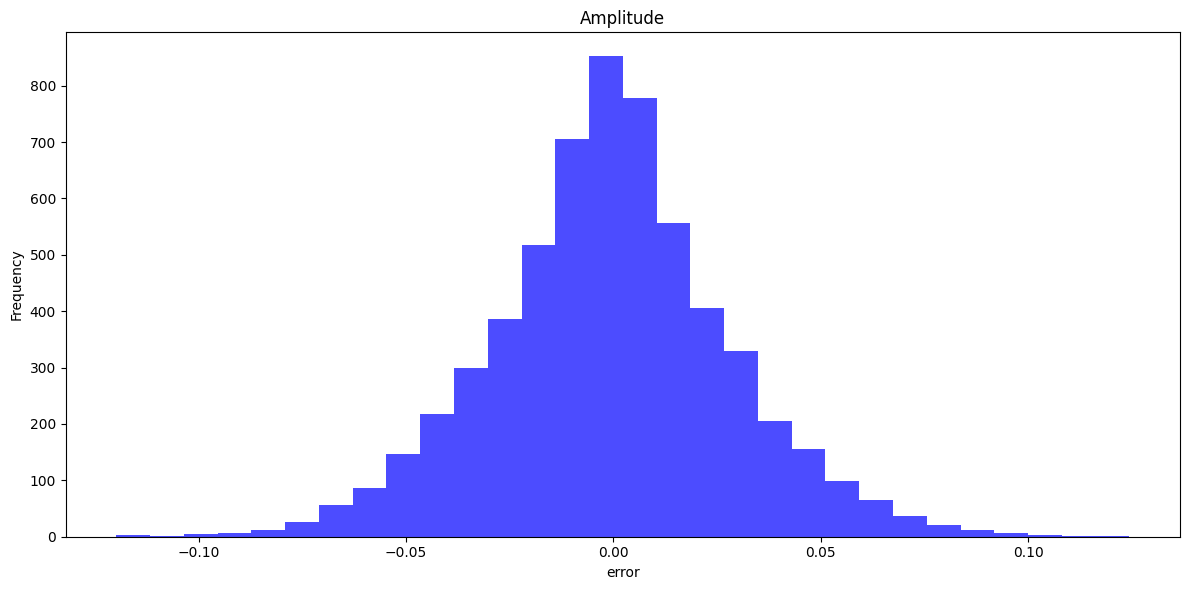

In [8]:
import matplotlib.pyplot as plt

# Plot the histograms
error_amplitude = (abs(np.array(ideal)) - abs(np.array(recover)))

fig, axs = plt.subplots(1, 1, figsize=(12, 6))  # 1 row, 2 columns

# Plot the amplitude error
axs.hist(error_amplitude.flatten(), bins=30, color='blue', alpha=0.7)
axs.set_title('Amplitude')
axs.set_xlabel('error')
axs.set_ylabel('Frequency')


# Display the figure
plt.tight_layout()  # Adjust layout to prevent overlap
plt.show()

# **Section 2: Photonic Matrix Implementation using Rectangular (Clements) Architecture**

In this section, we will implement a 3x3 photonic matrix using the **Clements architecture**. The matrix will be decomposed step by step into the necessary phases and components. The Clements architecture is a well-known method for building complex photonic circuits using a series of directional couplers, phase shifters, and other optical components.

We will first describe the components needed to create the 3x3 matrix and then proceed to implement the decomposition of this matrix into the corresponding phase shifts.

### **Clements Architecture Overview**

The Clements architecture is commonly used to realize unitary matrices in photonic systems. It works by combining directional couplers (MMIs) and phase shifters in a rectangular grid-like structure. Each coupling and phase shift corresponds to specific values in the matrix decomposition.

Here's an image of the general structure of the Clements architecture for a 3x3 matrix:

<img src="images/clements.png" alt="Drawing" style="width: 700px;"/>


### Decomposition Algorithm:

The decomposition of a unitary matrix in the Clements architecture is achieved using a sequence of 2x2 transformation matrices, denoted as $T_{m,n}(\theta, \phi)$, which represent beam splitters and phase shifters. These matrices perform operations between two optical channels $m$ and $n$.

---

 **T-matrix Definition:**
The transformation matrix $T_{m,n}(\theta, \phi)$ for a directional coupler with a reflectivity $\cos(\theta)$ and a phase shift $\phi$ is defined as:

$$
T_{m,n}(\theta, \phi) = 
\begin{bmatrix}
e^{i \phi}\sin(\frac{\theta}{2}) & \cos(\frac{\theta}{2}) \\
e^{i \phi} \cos(\frac{\theta}{2}) & -\sin(\frac{\theta}{2})
\end{bmatrix}
$$

Where:
- $\theta $: Coupling angle controlling power distribution.
- $\phi $: Phase shift applied to one of the channels.

---

 **Matrix Decomposition Process:**

1. **Starting Point:**
   - We begin with a target unitary matrix $ U $.

2. **Applying T-matrices:**
   - We multiply the matrix $ U $ by successive $T_{m,n}(\theta, \phi)$ matrices to "zero out" specific elements, transforming the matrix toward a triangular form.

3. **Diagonal Phase Correction:**
   - After the triangular form is obtained, a diagonal matrix $ D $ with phases on the diagonal is applied to correct for any residual phases.

---

 **Decomposition Example:**
For a matrix decomposition, the transformation follows this pattern:

$$
U = D \cdot \prod_{(m,n) \in S} T_{m,n}(\theta, \phi)
$$

Where:
- $ S $ defines the ordered sequence of 2x2 transformations.
- $ D $ is the diagonal matrix with complex elements of modulus 1.



<img src="images/algorithm.png" alt="Drawing" style="width: 600px;"/>


---


### Objectives of This Section:
- Implement a 3x3 photonic matrix using the Clements architecture.
- Decompose the matrix into the corresponding phases.
- Add errors to the matrix.


### **Exercise 3: Define the T-matrix Function**  

In this exercise, we will define the function that generates the **T-matrix** used in the Clements decomposition for a 3x3 photonic matrix. The matrix will perform a unitary transformation between rows $m$ and $n$ of the matrix while leaving the rest of the rows unchanged.  
To do so, first create an identity matrix of size 3x3. Use for example numpy.eye function.
Then subsitute the elements of the **$T_{mn}$** on the corresponding positions.

In [9]:
# Function to create the T-matrix for a 3x3 system
def T_matrix(m, n, theta, phi):
    """
    Create a 3x3 T-matrix applying the unitary transformation between rows m and n.
    """
    # Initialize the identity matrix
    T = np.eye(3, dtype=complex)
    
    # Define the 2x2 transformation matrix
    T_mn = np.array([
        [np.exp(1j * phi) * np.sin(theta / 2), np.cos(theta / 2)],
        [np.exp(1j * phi) * np.cos(theta / 2), -np.sin(theta / 2)]
    ])
    
    # Insert the T-matrix into the correct rows
    T[m, m] = T_mn[0, 0]
    T[n, n] = T_mn[1, 1]
    T[m, n] = T_mn[0, 1]
    T[n, m] = T_mn[1, 0]
    
    return T


In [10]:
# Check

theta = np.pi / 4
phi = np.pi / 2
T = T_matrix(0, 1, theta, phi)

T_expected = np.array([[ 2.34326020e-17+0.38268343j,  9.23879533e-01+0.j, 0.00000000e+00+0.j],
                       [ 5.65713056e-17+0.92387953j, -3.82683432e-01+0.j, 0.00000000e+00+0.j],
                       [ 0.00000000e+00+0.j, 0.00000000e+00+0.j, 1.00000000e+00+0.j]])

# Good function
print("T-matrix for m=0, n=1, theta=pi/4, phi=pi/2:")
print(f"Same amplitude: {np.allclose(abs(T), abs(T_expected))}")
print(f"Same phase: {np.allclose(np.angle(T), np.angle(T_expected))}")


T-matrix for m=0, n=1, theta=pi/4, phi=pi/2:
Same amplitude: True
Same phase: True


### **Exercise 4: Zeroing Elements in a 3x3 Matrix $U$ using the T-matrix**  

In this exercise, we will implement the decomposition of a 3x3 unitary matrix $U$ using the **Clements decomposition method**. Specifically, we will zero out specific elements of the matrix by applying three corresponding T-matrices.  

---

**How the T-matrix Affects $U$**  

The T-matrix performs a rotation between two rows of the matrix $U$ when multiplied from the left:

$$
U' = T_{m,n}(\theta, \phi) \cdot U
$$

Where:  
- $T_{m,n}(\theta, \phi)$ applies a unitary transformation between rows $m$ and $n$.
- $U'$ is the updated matrix after applying the T-matrix.

Similar behavior applies to the inverse $T_{m,n}^{-1}(\theta, \phi)$ affecting the columns $m$ and $n$.

---


**Steps for Zeroing Elements following the decomposition algorithm above. In the original algorithm the indices of an array go from 1 to N. Remember that in python indices go from 0 to N-1:**  

1. Zero out $U[2, 0]$ using $T_{0, 1}^{-1}$.  
2. Zero out $U[1, 0]$ using $T_{0, 1}$. 
3. Zero out $U[2, 1]$ using $T_{1, 2}$.  

Then, we obtain:
$T_{1, 2}T_{0, 1}UT_{0, 1}^{-1} = D$

By multiplying by the inverse of the matrices we arrive to:
$U = T_{0, 1}^{-1}T_{1, 2}^{-1}DT_{0, 1}$

And rearranging:
$U = D^{'}T_{0, 1}^{'}T_{1, 2}^{'}T_{0, 1}$

---

**Mathematical Derivation:**  

To zero out an element $U[row, column]$, we compute:  
If $T_{m,n}(\theta, \phi)U$:

$$
\phi = \arg(U[row, column]) - \arg(U[row - 1, column])
$$  

$$
\theta = 2\arctan \left(\frac{|U[row - 1, column]|}{|U[row, column])|}\right)
$$  


If $UT^{-1}_{m,n}(\theta, \phi)$:

$$
\phi = \arg(U[row, column]) - \arg(U[row, column + 1]) + \pi
$$  

$$
\theta = 2\arctan \left(\frac{|U[row, column + 1]|}{|U[row, column])|}\right)
$$ 


---




**Write the function to null an element in the position $U[row, column]$ using the previous formulas:**

In [ ]:
def compute_zeroing_params(U, row, column, mode="normal"):
    """
  
    """
    if mode == "normal":
        # Compute parameters when applying T * U
        phi = np.angle(U[row, column]) - np.angle(U[row - 1, column])
        theta = 2 * np.arctan(np.abs(U[row - 1, column]) / np.abs(U[row, column]))
    elif mode == "inverse":
        # Compute parameters when applying U * T^(-1)
        phi = np.angle(U[row, column]) - np.angle(U[row, column + 1]) + np.pi
        theta = 2 * np.arctan(np.abs(U[row, column + 1]) / np.abs(U[row, column]))
    else:
        raise ValueError("Invalid mode. Use 'normal' or 'inverse'.")
    
    return theta, phi



**Now, lets go with the first step. Zero out $U[2, 0]$ using $T_{0, 1}^{-1}$. Check that you have correctly null the element.**

In [13]:
# The unitary matrix to decompose is the following

from scipy.stats import unitary_group
np.random.seed(0)

# Generate a 3x3 unitary matrix
N = 3
U = unitary_group.rvs(N)

print(U)

[[ 0.56078693+0.13052803j -0.31583062-0.08879493j  0.59273587+0.45772385j]
 [ 0.7123732 +0.2419316j   0.39227097-0.22401521j -0.2246578 -0.42363082j]
 [ 0.30203025+0.10607406j -0.38000351+0.7374988j  -0.45253113+0.06659165j]]


In [23]:
# First, calculate the required phases to null the element.
theta_1, phi_1 = compute_zeroing_params(U, 1, 0, mode="inverse")

print(f"Theta values is: {theta_1: .3f}")
print(f"Phi values is: {phi_1: .3f}")

Theta values is:  1.081
Phi values is:  3.988


In [21]:
# Check that the element has been nulled
T_01_0 = T_matrix(0, 1, theta_1, phi_1) # Create the matrix T
T_inverse_01_0 = np.linalg.inv(T_01_0) # Create the inverse of the matrix T

U_new = U @ T_inverse_01_0 # Compute the matrix multiplication

print(f"New zeroed matrix is: \n")
print(np.round(U_new, 5))

New zeroed matrix is: 

[[-0.51241+0.09551j -0.23987+0.33155j  0.59274+0.45772j]
 [-0.     +0.j      -0.76203+0.43517j -0.22466-0.42363j]
 [-0.46972+0.71251j -0.0441 -0.24602j -0.45253+0.06659j]]


**Compute the second step. Zero out $U[1, 0]$ using $T_{0, 1}$.  Check that you have correctly null the element.**

In [22]:
# First, calculate the required phases to null the element.
theta_2, phi_2 = compute_zeroing_params(U_new, 1, 0, mode="normal")

print(f"Theta values is: {theta_2: .3f}")
print(f"Phi values is: {phi_2: .3f}")

Theta values is:  3.142
Phi values is:  0.184


In [24]:
# Check that the element has been nulled
T_01_1 = T_matrix(0, 1, theta_2, phi_2) # Create the matrix T
T_inverse_01_1 = np.linalg.inv(T_01_1) # Create the inverse of the matrix T

U_new_2 = T_01_1 @ U_new   # Compute the matrix multiplication

print(f"New zeroed matrix is: \n")
print(np.round(U_new_2, 5))

New zeroed matrix is: 

[[-0.52124+0.j      -0.29656+0.28199j  0.49883+0.55858j]
 [ 0.     +0.j       0.76203-0.43517j  0.22466+0.42363j]
 [-0.46972+0.71251j -0.0441 -0.24602j -0.45253+0.06659j]]


**Compute the third step. Zero out $U[2, 1]$ using $T_{1, 2}$.  Check that you have correctly null the element.**

In [25]:
# First, calculate the required phases to null the element.
theta_3, phi_3 = compute_zeroing_params(U_new_2, 2, 1, mode="normal")

print(f"Theta values is: {theta_3: .3f}")
print(f"Phi values is: {phi_3: .3f}")

Theta values is:  2.587
Phi values is: -1.229


In [26]:
# Check that the element has been nulled
T_12 = T_matrix(1, 2, theta_3, phi_3) # Create the matrix T
T_inverse_12 = np.linalg.inv(T_12) # Create the inverse of the matrix T

U_new_3 = T_12 @ U_new_2    # Compute the matrix multiplication

print(f"New zeroed matrix is: \n")
print(np.round(U_new_3, 5))

New zeroed matrix is: 

[[-0.52124+0.j      -0.29656+0.28199j  0.49883+0.55858j]
 [-0.12867+0.19518j -0.161  -0.89812j  0.3323 -0.0489j ]
 [ 0.45176-0.68526j  0.     -0.j       0.56517-0.08317j]]


---
We have completed this, where D = U_new_3
$T_{1, 2}T_{0, 1}UT_{0, 1}^{-1} = D$

It is straightforward to arrive to:
$U = T_{0, 1}^{-1}T_{1, 2}^{-1}DT_{0, 1}$

To obtain the final decomposition $U = D_{2}T_{0, 1}^{'}T_{1, 2}^{'}T_{0, 1}$ we are going to repeat the previous procedure as follows:

1. $T_{1, 2}^{-1}D$ is a unitary matrix $U_{aux}$. We can zero out the element at position (2,1) multiplying by a $T_{1, 2}^{-1}$ and thus $U_{aux}T_{1, 2}^{-1}$ = $T_{1, 2}^{-1}DT_{1, 2}^{-1}$ = $D_{1}$, and rearranging $U_{aux}$ = $D_{2}T_{1, 2}$. We have then reordered the position of the matrices.
2. Repeating the process with $T_{0, 1}^{-1}D_{1}$ we finally arrive to the desired $U = D_{2}T_{0, 1}^{'}T_{1, 2}^{'}T_{0, 1}$

---
**Now, use the previous code to obtain $T_{1, 2}^{-1}D$ = $D_{1}$$T_{1, 2}$**

In [27]:
# First, calculate the required phases to null the element.
U_aux_1 = T_inverse_12 @ U_new_3
theta_3_1, phi_3_1 = compute_zeroing_params(U_aux_1, 2, 1, mode="inverse")

print(f"Theta values is: {theta_3_1: .3f}")
print(f"Phi values is: {phi_3_1: .3f}")

Theta values is:  2.141
Phi values is: -1.602


In [28]:
# Check that the multiplications are equal
T_12_1 = T_matrix(1, 2, theta_3_1, phi_3_1) # Create the matrix T
T_inverse_12_1 = np.linalg.inv(T_12_1) # Create the inverse of the matrix T

D_1 = U_aux_1 @ T_inverse_12_1    # Compute the matrix multiplication

print(f"Same amplitude: {np.allclose(abs(T_inverse_12 @ U_new_3), abs(D_1 @ T_12_1))}")
print(f"Same phase: {np.allclose(np.angle(T_inverse_12 @ U_new_3), np.angle(D_1 @ T_12_1))}")

Same amplitude: True
Same phase: True


**Finally, use the previous code to obtain $T_{0, 1}^{-1}D_{1}$ = $D_{2}T_{0, 1}$**

In [29]:
# First, calculate the required phases to null the element.
U_aux_2 = T_inverse_01_1 @ D_1
theta_2_1, phi_2_1 = compute_zeroing_params(U_aux_2, 1, 0, mode="inverse")

print(f"Theta values is: {theta_2_1: .3f}")
print(f"Phi values is: {phi_2_1: .3f}")

Theta values is:  3.142
Phi values is:  8.088


In [30]:
# Check that the multiplications are equal
T_01_2 = T_matrix(0, 1, theta_2_1, phi_2_1) # Create the matrix T
T_inverse_01_2 = np.linalg.inv(T_01_2) # Create the inverse of the matrix T

D_2 = U_aux_2 @ T_inverse_01_2    # Compute the matrix multiplication

print(f"Same amplitude: {np.allclose(abs(T_inverse_01_1 @ D_1), abs(D_2 @ T_01_2))}")
print(f"Same phase: {np.allclose(np.angle(T_inverse_01_1 @ D_1), np.angle(D_2 @ T_01_2))}")

Same amplitude: True
Same phase: True


**We can recover the initial matrix U as a multiplication of T matrices and a diagonal D**

In [31]:
U_recovered = D_2 @ T_01_2 @ T_12_1 @ T_01_0

print(f"Initial matrix: \n{np.round(U, 3)}\n")
print(f"Recovered matrix: \n{np.round(U_recovered, 3)}\n")

print(f"Same amplitude: {np.allclose(abs(U), abs(U_recovered))}")
print(f"Same phase: {np.allclose(np.angle(U), np.angle(U_recovered))}")

Initial matrix: 
[[ 0.561+0.131j -0.316-0.089j  0.593+0.458j]
 [ 0.712+0.242j  0.392-0.224j -0.225-0.424j]
 [ 0.302+0.106j -0.38 +0.737j -0.453+0.067j]]

Recovered matrix: 
[[ 0.561+0.131j -0.316-0.089j  0.593+0.458j]
 [ 0.712+0.242j  0.392-0.224j -0.225-0.424j]
 [ 0.302+0.106j -0.38 +0.737j -0.453+0.067j]]

Same amplitude: True
Same phase: True


## **Impact of Phase Errors on Fidelity**  

Introducing errors in the phases of unitary matrices affects their fidelity. **Fidelity** measures how close an obtained matrix $ U_{\text{obtained}} $ is to the ideal matrix $ U_{\text{ideal}} $. A fidelity value of 1 indicates that the two matrices are identical, while lower values represent deviations due to imperfections such as phase errors.  

---

### **Fidelity Formula:**  

The fidelity between the ideal matrix $ U_{\text{ideal}} $ and the obtained matrix $ U_{\text{obtained}} $ is computed as:  

$
F(U_{\text{exp}}, U) = \left| \frac{\text{tr}(U^\dagger U_{\text{exp}})}{\sqrt{N \cdot \text{tr}(U_{\text{exp}}^\dagger U_{\text{exp}})}} \right|^2
$

Where:
- $ U^\dagger $ is the Hermitian conjugate (complex conjugate transpose) of the ideal matrix $ U $.
- $ \text{tr}(\cdot)$ represents the trace of a matrix (the sum of its diagonal elements).
- $ N $ is the dimension of the matrix.

---

### **Fidelity Interpretation:**  

- **$ F = 1 $:** Perfect fidelity (matrices are identical).  
- **$ F < 1 $:** Matrices differ due to errors.  



In [32]:
# Function to compute fidelity
def fidelity(U_ideal, U_obtained):
    """
    Computes the fidelity between the ideal and obtained unitary matrices.
    """
    N = U_ideal.shape[0]
    numerator = np.abs(np.trace(U_ideal.conj().T @ U_obtained))**2
    denominator = N * np.real(np.trace(U_obtained.conj().T @ U_obtained))
    
    return numerator / denominator

**We will simulate the impact of errors in the unitary matrix on the fidelity** 

1. Create a unitary matrix
2. Add gaussian noise. Hint: Create a random gaussian matrix with a standard deviation std and add it to the ideal unitary matrix. This will be the experimental unitary.
3. Compute the fidelity.
4. Repeat for N = 1000 and plot the fidelity results in an histogram.

Plot the fidelity distribution for std = 0.05, 0.15, 0.25


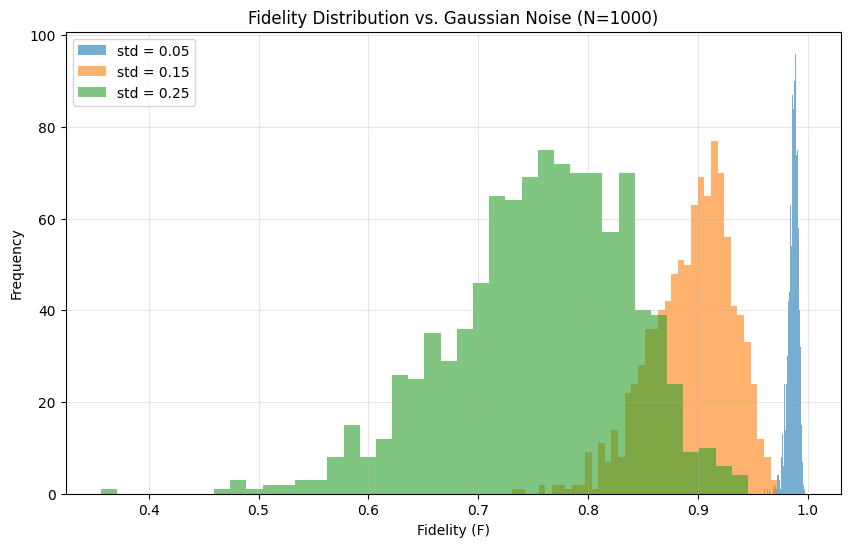

In [34]:
### CODE ###
import matplotlib.pyplot as plt

N_trials = 1000
std_devs = [0.05, 0.15, 0.25]
fidelity_data = {std: [] for std in std_devs}

# 1. Create a unitary matrix
N_dim = 3
U_ideal = unitary_group.rvs(N_dim)

for std in std_devs:
    for _ in range(N_trials):
        # 2. Add gaussian noise (complex noise to simulate phase/amplitude errors)
        noise = np.random.normal(0, std, (N_dim, N_dim)) + 1j * np.random.normal(0, std, (N_dim, N_dim))
        U_obtained = U_ideal + noise
        
        # 3. Compute the fidelity
        f = fidelity(U_ideal, U_obtained)
        fidelity_data[std].append(f)

# 4. Plot the fidelity results in a histogram
plt.figure(figsize=(10, 6))
for std in std_devs:
    plt.hist(fidelity_data[std], bins=40, alpha=0.6, label=f'std = {std}')

plt.title('Fidelity Distribution vs. Gaussian Noise (N=1000)')
plt.xlabel('Fidelity (F)')
plt.ylabel('Frequency')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

---------------- Include some comments on the impact of the errors on the fidelity of the matrices -------------------------------


   con sigma = 0.05 la fidelidad se queda muy concentrada alrededor de 1, lo que lo hace robusto a imperfecciones del hardware. con 0.15 y 0.25 la fidelidad decae bastante y la distribución de probabilidad se ensancha, lo que nos dice que la matriz experimental implementada ya no representa de forma fiable a la matriz unitaria target.

**End of the notebook. Thanks for your contribution**